# module 1

In [1]:
import scanpy as sc

adata = sc.read_10x_mtx(
    'data/filtered_gene_bc_matrices/hg19/',
    var_names='gene_symbols'
)
adata.var_names_make_unique()
print(adata)

AnnData object with n_obs × n_vars = 2700 × 32738
    var: 'gene_ids'


In [2]:
# ミトコンドリア遺伝子の識別
adata.var['mt'] = adata.var_names.str.startswith('MT-')

# QC 指標の計算
sc.pp.calculate_qc_metrics(
    adata, qc_vars=['mt'], percent_top=None, log1p=False, inplace=True
)

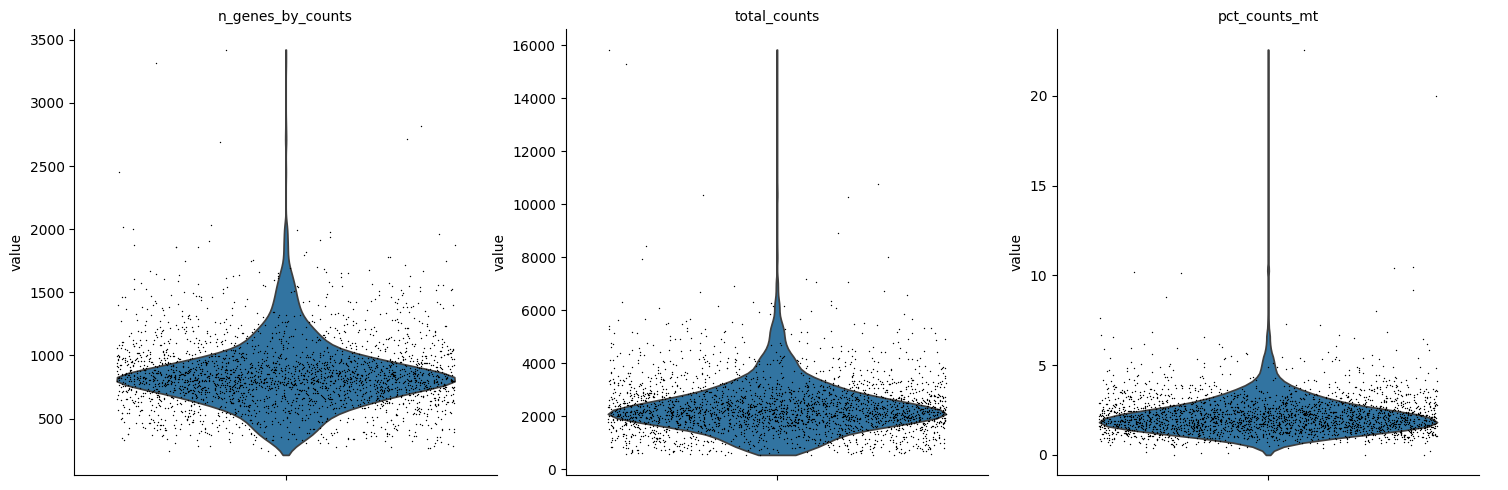

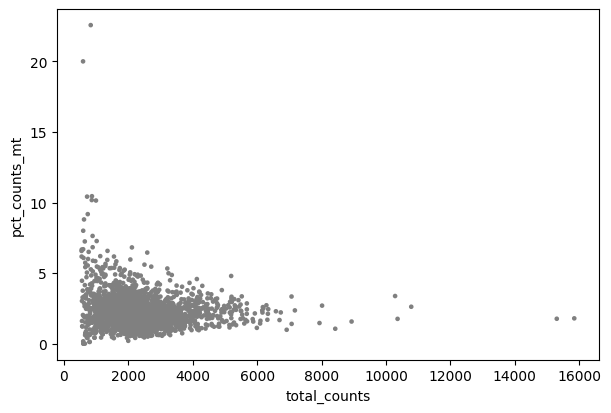

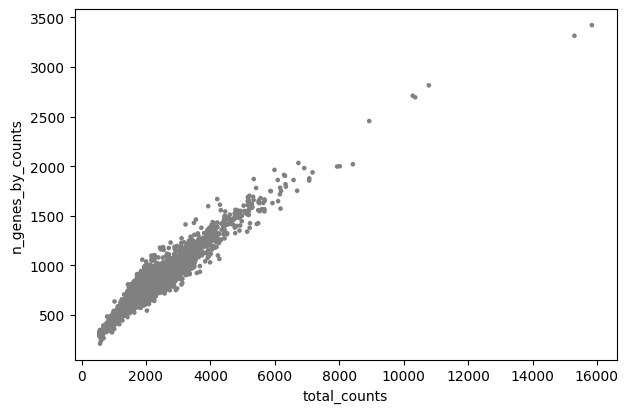

/Users/kimuraiwao/Docs/study-sc-rna-seq/course/.venv/lib/python3.12/site-packages/scanpy/preprocessing/_simple.py:279: ImplicitModificationWarning: Trying to modify attribute `.var` of view, initializing view as actual.
  adata.var["n_cells"] = number


In [3]:
# 可視化
sc.pl.violin(
    adata,
    ['n_genes_by_counts', 'total_counts', 'pct_counts_mt'],
    jitter=0.4, multi_panel=True
)
sc.pl.scatter(adata, x='total_counts', y='pct_counts_mt')
sc.pl.scatter(adata, x='total_counts', y='n_genes_by_counts')

# フィルタリング
adata = adata[adata.obs.n_genes_by_counts < 2500, :]
adata = adata[adata.obs.pct_counts_mt < 5, :]
sc.pp.filter_genes(adata, min_cells=3)

## モジュール 2：正規化と高変動遺伝子選択

In [4]:
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata.raw = adata  # 正規化済みデータを保存

In [5]:
sc.pp.highly_variable_genes(adata, min_mean=0.0125, max_mean=3, min_disp=0.5)
print(f"HVG 数: {adata.var.highly_variable.sum()}")  # 通常 2,000〜4,000
adata = adata[:, adata.var.highly_variable]

HVG 数: 1826


In [6]:
sc.pp.scale(adata, max_value=10)


/opt/homebrew/Cellar/python@3.12/3.12.11/Frameworks/Python.framework/Versions/3.12/lib/python3.12/functools.py:912: UserWarning: Received a view of an AnnData. Making a copy.
  return dispatch(args[0].__class__)(*args, **kw)
/opt/homebrew/Cellar/python@3.12/3.12.11/Frameworks/Python.framework/Versions/3.12/lib/python3.12/functools.py:912: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


## モジュール 3：次元削減 — PCA と UMAP の数理


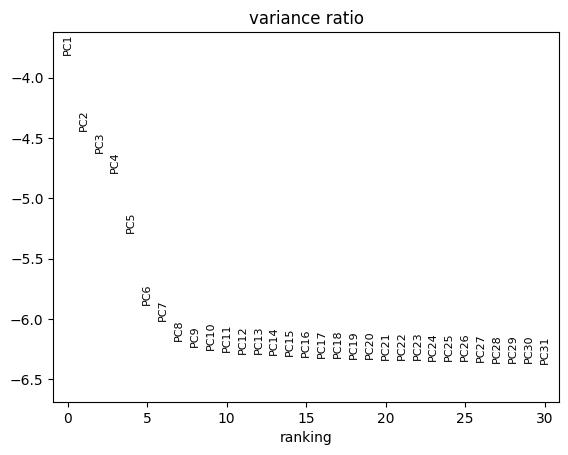

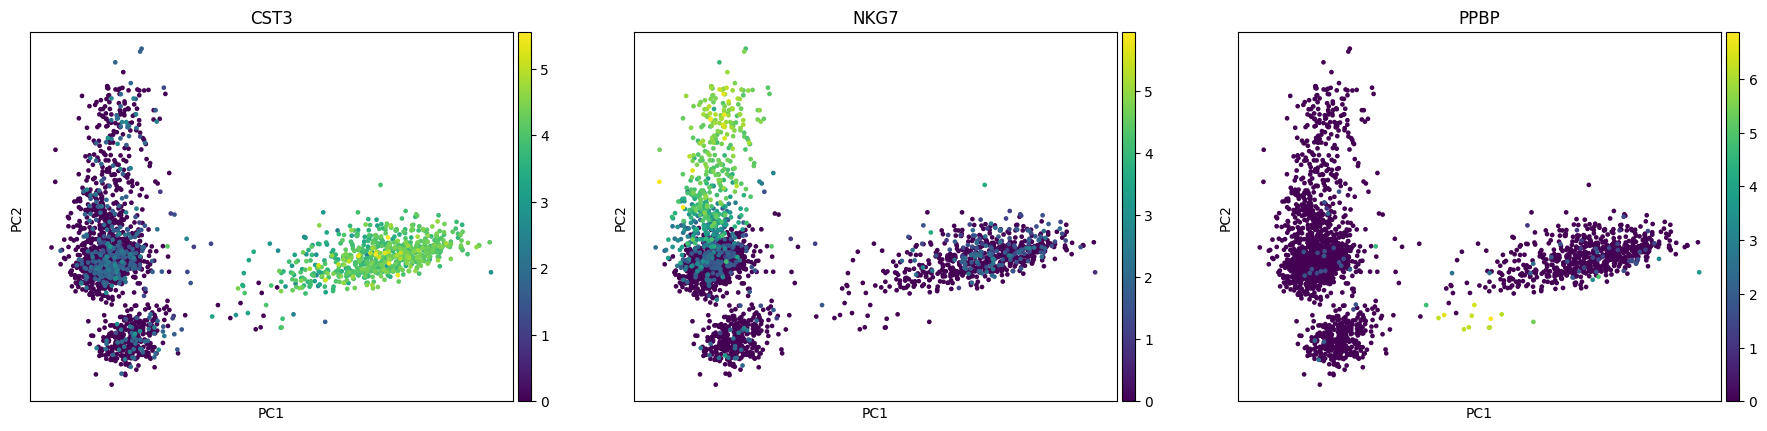

In [7]:
sc.tl.pca(adata, svd_solver='arpack')
sc.pl.pca_variance_ratio(adata, log=True)  # elbow plot で PC 数を決定
sc.pl.pca(adata, color=['CST3', 'NKG7', 'PPBP'])

In [8]:
sc.pp.neighbors(adata, n_neighbors=10, n_pcs=40)


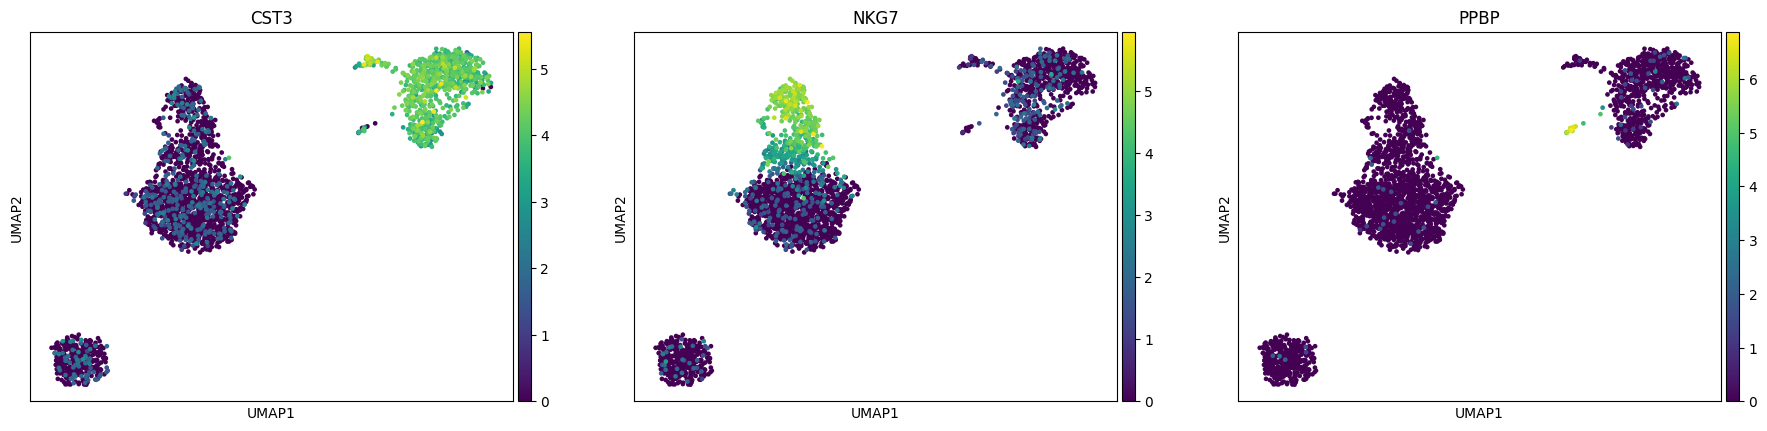

In [9]:
sc.tl.umap(adata)
sc.pl.umap(adata, color=['CST3', 'NKG7', 'PPBP'])

## モジュール 4：クラスタリングとグラフ分割


/var/folders/gf/d7ywxmmd4s98mb0t53rxztdr0000gn/T/ipykernel_34790/361093697.py:1: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  sc.tl.leiden(adata, resolution=0.5)


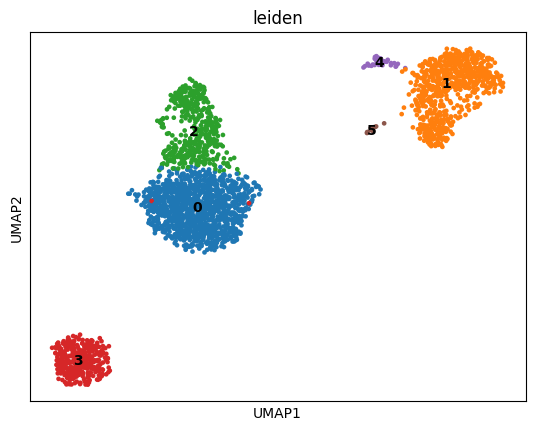

In [10]:
sc.tl.leiden(adata, resolution=0.5)
sc.pl.umap(adata, color=['leiden'], legend_loc='on data')


## モジュール 5：細胞型アノテーション — マーカー遺伝子と仮説検定


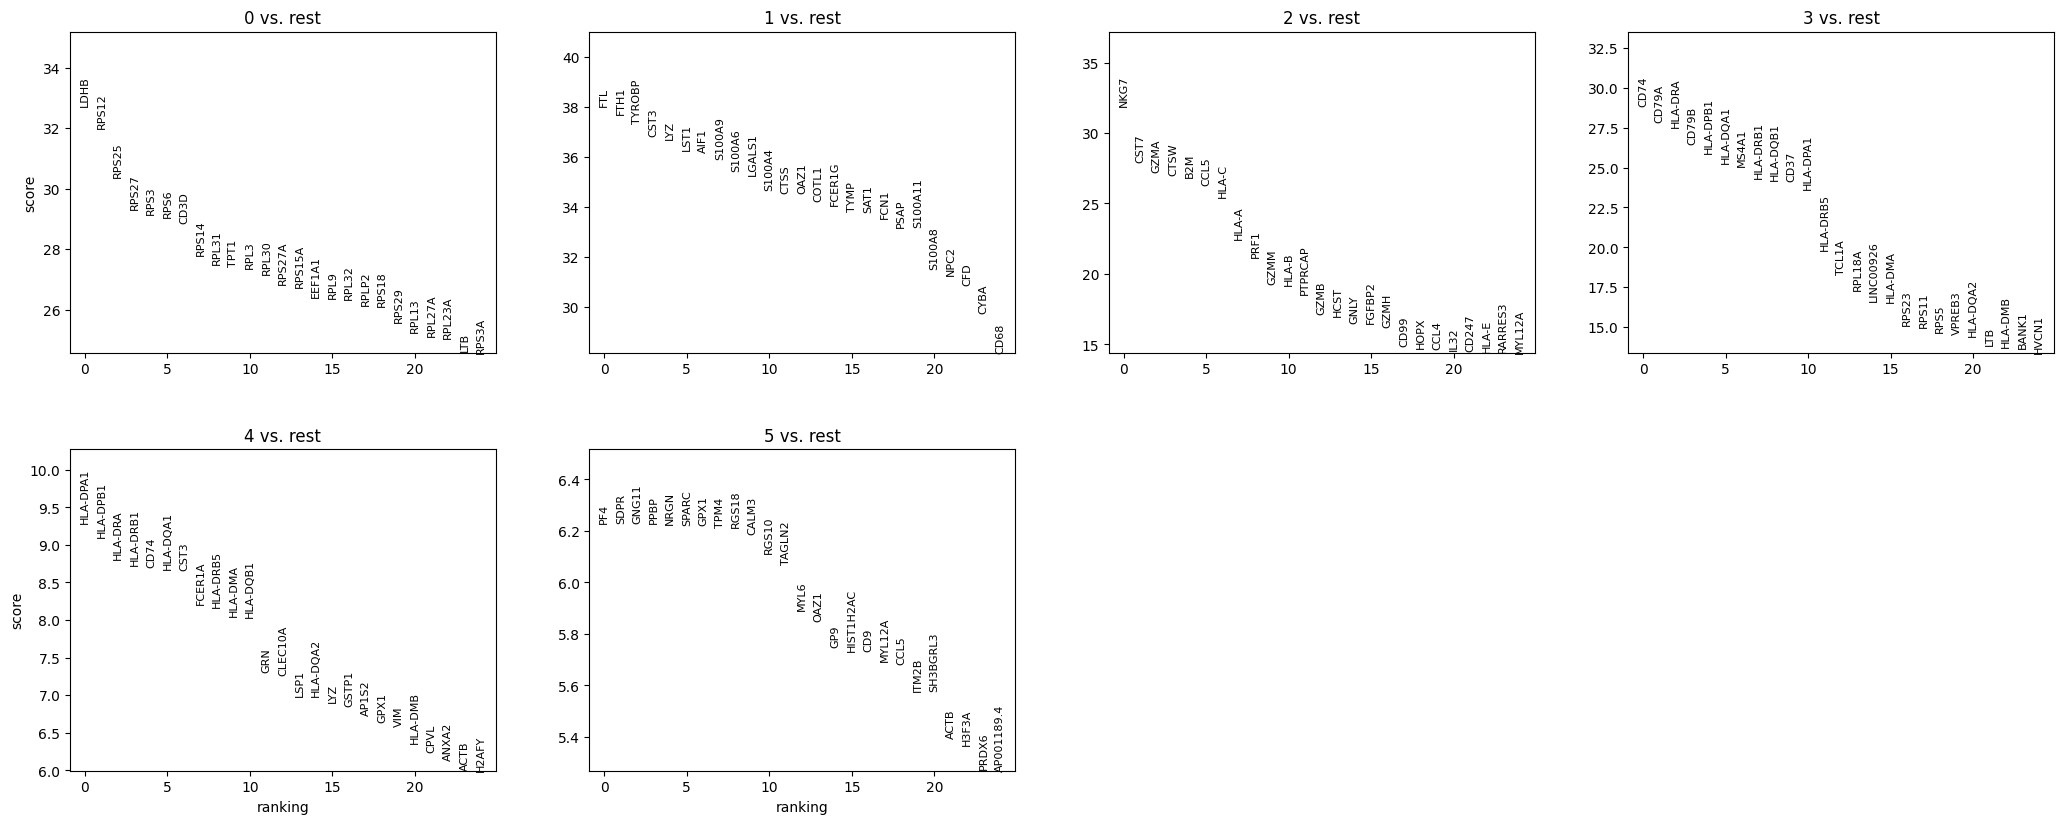

In [11]:

sc.tl.rank_genes_groups(adata, 'leiden', method='wilcoxon')
sc.pl.rank_genes_groups(adata, n_genes=25, sharey=False)


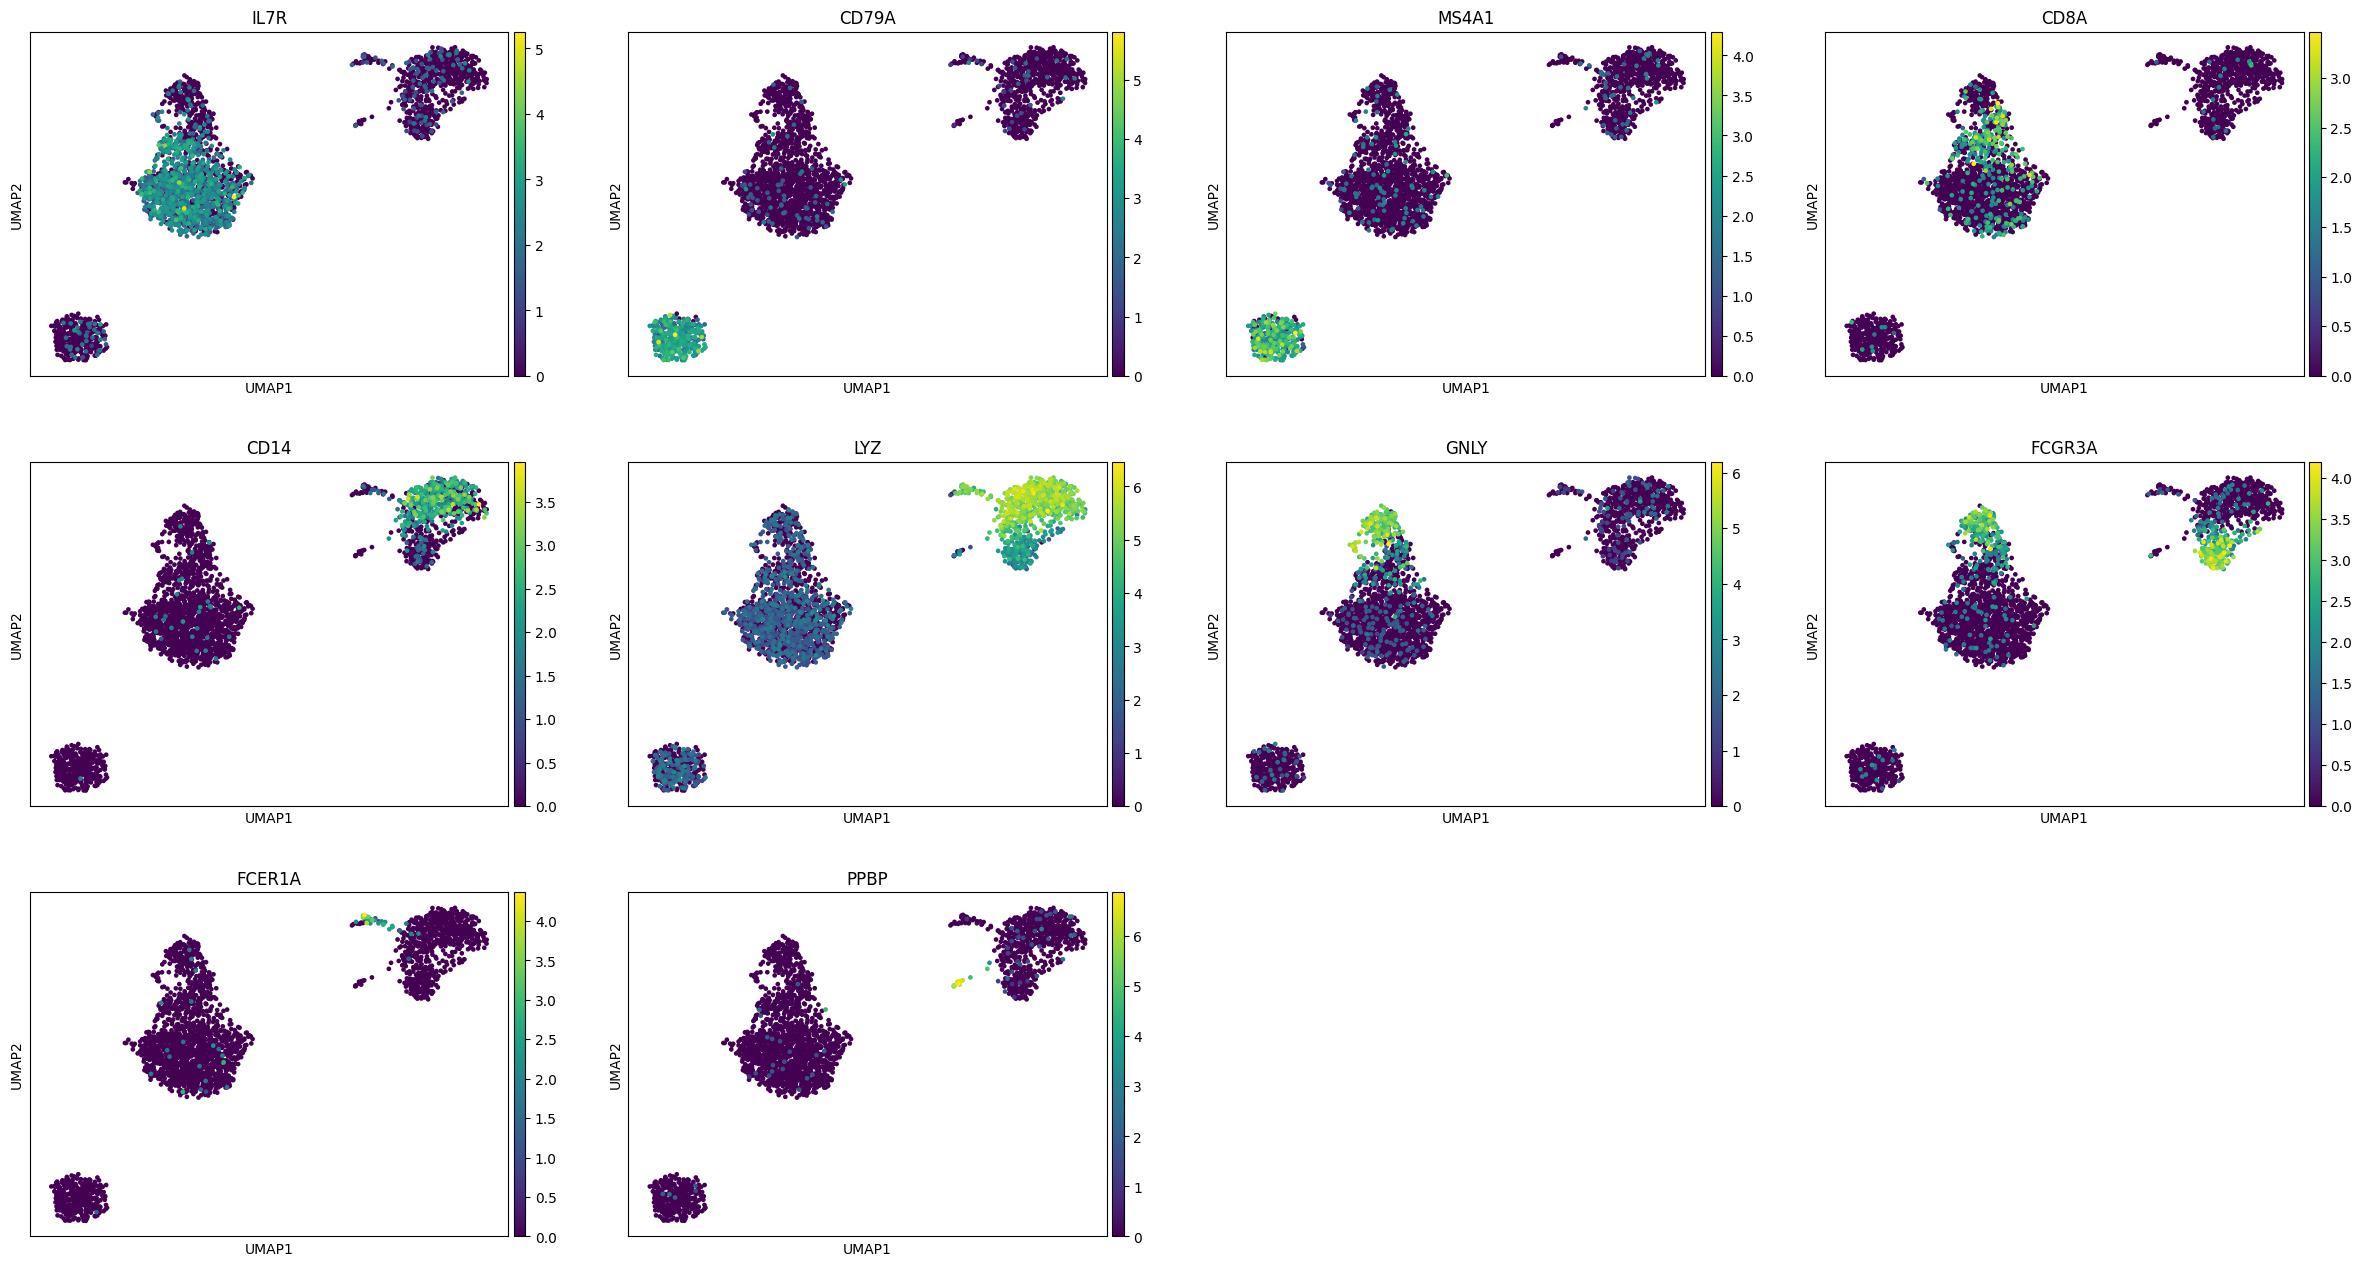

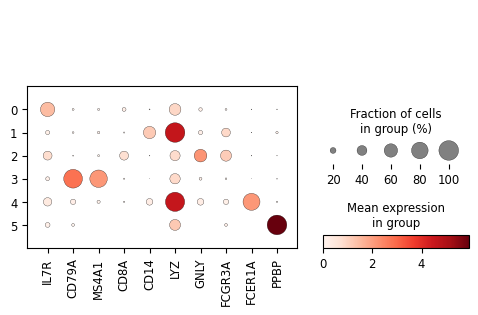

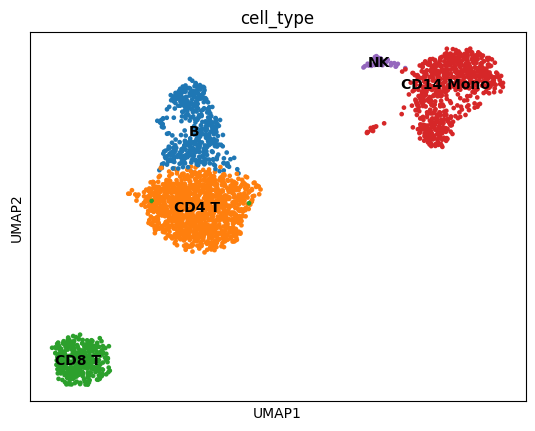

In [12]:

marker_genes = ['IL7R', 'CD79A', 'MS4A1', 'CD8A', 'CD14', 'LYZ',
                'GNLY', 'FCGR3A', 'FCER1A', 'PPBP']
sc.pl.umap(adata, color=marker_genes)
sc.pl.dotplot(adata, marker_genes, groupby='leiden')

# アノテーションの割り当て（例）
cell_type_map = {
    '0': 'CD4 T', '1': 'CD14 Mono', '2': 'B',
    '3': 'CD8 T', '4': 'NK', '5': 'CD14 Mono',
    '6': 'Dendritic', '7': 'CD16 Mono', '8': 'Platelet'
}
adata.obs['cell_type'] = adata.obs['leiden'].map(cell_type_map)
sc.pl.umap(adata, color=['cell_type'], legend_loc='on data')


## モジュール 6：差次発現解析（DEG） — 負の二項分布モデル


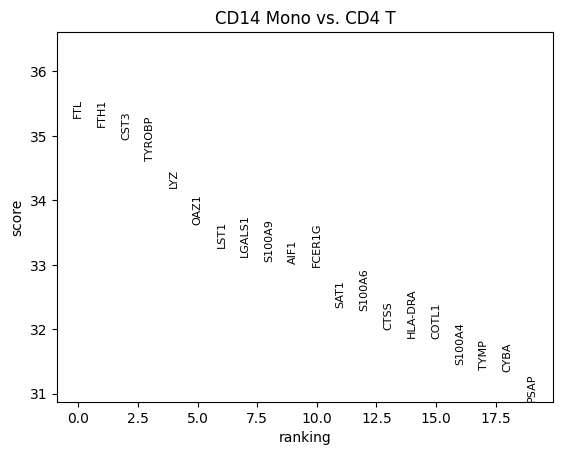

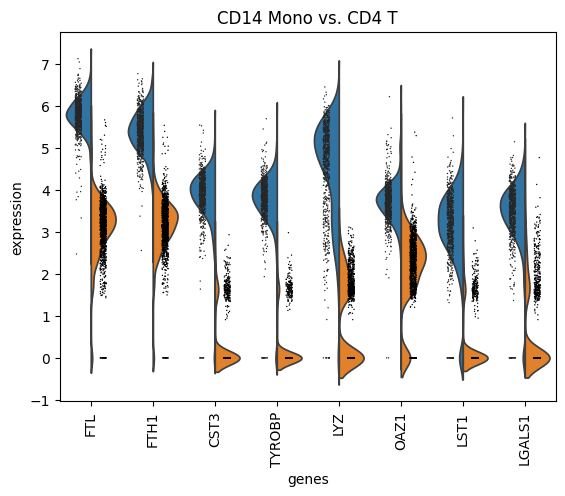

In [13]:

# 特定の 2 グループ間の DEG（Wilcoxon 検定）
sc.tl.rank_genes_groups(
    adata, groupby='cell_type',
    groups=['CD14 Mono'], reference='CD4 T',
    method='wilcoxon'
)
sc.pl.rank_genes_groups(adata, groups=['CD14 Mono'])
sc.pl.rank_genes_groups_violin(adata, groups='CD14 Mono', n_genes=8)


In [17]:

import numpy as np
import pandas as pd

# ※ PBMC 3k データには 'sample' 列がないため，以下は複数サンプルがある場合の例示
# adata.obs['sample'] 列が存在する前提

pseudobulk_rows = []
pseudobulk_index = []
for (sample, cell_type), idx in adata.obs.groupby(['sample', 'cell_type']).groups.items():
    mat = adata[idx, :].X
    # 疎行列（scipy sparse）は sum(axis=0) が matrix 型を返すため，1D 配列に変換する
    counts = np.asarray(mat.sum(axis=0)).flatten()
    pseudobulk_rows.append(counts)
    pseudobulk_index.append((sample, cell_type))

pseudobulk = pd.DataFrame(
    pseudobulk_rows,
    index=pd.MultiIndex.from_tuples(pseudobulk_index, names=['sample', 'cell_type']),
    columns=adata.var_names,
)


KeyError: 'samples'

## モジュール 7：発展 — 軌跡推定と擬似時間


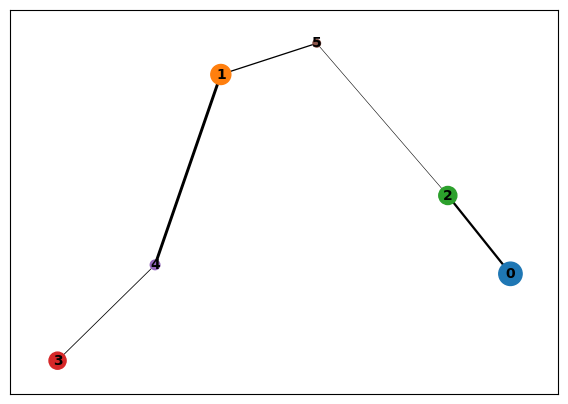

In [20]:

sc.tl.paga(adata, groups='leiden')
sc.pl.paga(adata, plot=True, threshold=0.03)


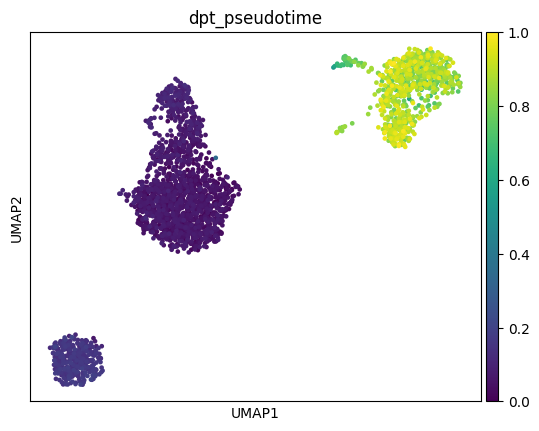

In [21]:

import numpy as np

# 根細胞（幹細胞に近い細胞）を指定
adata.uns['iroot'] = np.flatnonzero(adata.obs['leiden'] == '0')[0]
sc.tl.dpt(adata)
sc.pl.umap(adata, color=['dpt_pseudotime'], color_map='viridis')


Filtered out 20801 genes that are detected 20 counts (shared).
Normalized count data: X, spliced, unspliced.
computing neighbors
    finished (0:00:00) --> added 
    'distances' and 'connectivities', weighted adjacency matrices (adata.obsp)
computing moments based on connectivities


/var/folders/gf/d7ywxmmd4s98mb0t53rxztdr0000gn/T/ipykernel_34790/2917770548.py:8: DeprecationWarning: Automatic neighbor calculation is deprecated since scvelo==0.4.0 and will be removed in a future version of scVelo. Please compute neighbors first with Scanpy.
  scv.pp.moments(adata_velo, n_pcs=30, n_neighbors=30)
/Users/kimuraiwao/Docs/study-sc-rna-seq/course/.venv/lib/python3.12/site-packages/scvelo/preprocessing/moments.py:71: DeprecationWarning: `neighbors` is deprecated since scvelo==0.4.0 and will be removed in a future version of scVelo. Please compute neighbors with Scanpy.
  neighbors(


    finished (0:00:01) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)
recovering dynamics (using 1/8 cores)


  0%|          | 0/2722 [00:00<?, ?gene/s]

    finished (0:08:11) --> added 
    'fit_pars', fitted parameters for splicing dynamics (adata.var)
computing velocities
    finished (0:00:03) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)
computing velocity graph (using 1/8 cores)


  0%|          | 0/3696 [00:00<?, ?cells/s]

    finished (0:00:07) --> added 
    'velocity_graph', sparse matrix with cosine correlations (adata.uns)
computing velocity embedding
    finished (0:00:00) --> added
    'velocity_umap', embedded velocity vectors (adata.obsm)


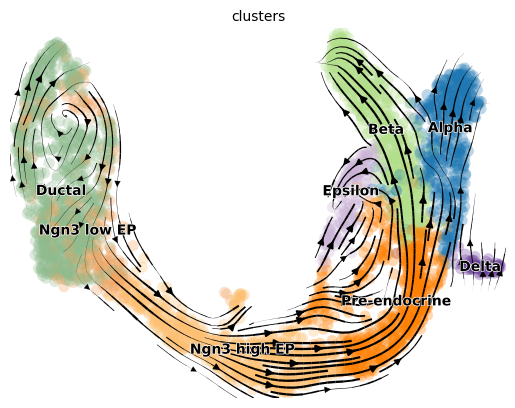

In [25]:
import scvelo as scv

# scVelo サンプルデータ（膵臓β細胞分化）を使用
# unspliced / spliced カウントが含まれた AnnData が返される
adata_velo = scv.datasets.pancreas()

scv.pp.filter_and_normalize(adata_velo, min_shared_counts=20)
scv.pp.moments(adata_velo, n_pcs=30, n_neighbors=30)

# dynamical モデルの前に splicing dynamics を推定する
scv.tl.recover_dynamics(adata_velo)
scv.tl.velocity(adata_velo, mode='dynamical')
scv.tl.velocity_graph(adata_velo)
scv.pl.velocity_embedding_stream(adata_velo, basis='umap', color='clusters')
